# Лабораторна робота 10. Завдання 3. Аугментація і тонке налаштування на обмеженому наборі коти-собаки: VGG16

## Завантаження набору даних з Google Диска

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import glob, shutil

# шукаємо архів dogs-vs-cats.zip з Kaggle у будь-якій папці Google Диска
found = glob.glob('/content/drive/MyDrive/**/dogs-vs-cats*.zip', recursive=True)
print(found)
assert found, 'Архів dogs-vs-cats.zip не знайдено на Google Диску'
shutil.copy(found[0], '/content/dogs-vs-cats.zip')

['/content/drive/MyDrive/dogs-vs-cats.zip']


'/content/dogs-vs-cats.zip'

In [3]:
!unzip -q -o /content/dogs-vs-cats.zip -d /content/dogs-vs-cats
!unzip -q -o /content/dogs-vs-cats/train.zip -d /content/dogs-vs-cats
!ls /content/dogs-vs-cats/train | wc -l

25000


## Обмежений набір даних: 2000 / 500 / 500 зображень кожного класу

In [4]:
%%writefile prepare_small_dataset.py
"""Підготовка обмеженого набору даних Dogs vs. Cats для лабораторної роботи 10.

З 25 000 зображень train.zip з Kaggle формується невеликий набір: по 2000 зображень кожного класу
для навчання, по 500 для перевірки і по 500 для тестування. Усі зображення в наборах різні.
"""
import os
import shutil

# Каталог з набором даних (розпакований train.zip з Kaggle)
data_dir = '/content/dogs-vs-cats/train'
# Каталог з даними для навчання
train_dir = 'train'
# Каталог з даними для перевірки
val_dir = 'val'
# Каталог з даними для тестування
test_dir = 'test'
# Кількість зображень одного класу в кожному наборі
nb_train, nb_val, nb_test = 2000, 500, 500


def create_directory(dir_name):
    """Створює каталог dir_name з підкаталогами cats і dogs (старий каталог видаляється)."""
    if os.path.exists(dir_name):
        shutil.rmtree(dir_name)
    os.makedirs(os.path.join(dir_name, "cats"))
    os.makedirs(os.path.join(dir_name, "dogs"))


def copy_images(start_index, end_index, source_dir, dest_dir):
    """Копіює зображення котів і собак з номерами від start_index до end_index у підкаталоги cats і dogs."""
    for i in range(start_index, end_index):
        shutil.copy2(os.path.join(source_dir, "cat." + str(i) + ".jpg"), os.path.join(dest_dir, "cats"))
        shutil.copy2(os.path.join(source_dir, "dog." + str(i) + ".jpg"), os.path.join(dest_dir, "dogs"))


for d in (train_dir, val_dir, test_dir):
    create_directory(d)

# 0-1999 - навчання, 2000-2499 - перевірка, 2500-2999 - тестування
copy_images(0, nb_train, data_dir, train_dir)
copy_images(nb_train, nb_train + nb_val, data_dir, val_dir)
copy_images(nb_train + nb_val, nb_train + nb_val + nb_test, data_dir, test_dir)

for d in (train_dir, val_dir, test_dir):
    print(d, ': cats -', len(os.listdir(os.path.join(d, "cats"))), ', dogs -', len(os.listdir(os.path.join(d, "dogs"))))


Writing prepare_small_dataset.py


In [5]:
!python prepare_small_dataset.py

train : cats - 2000 , dogs - 2000
val : cats - 500 , dogs - 500
test : cats - 500 , dogs - 500


## Структура каталогів

In [6]:
!find train val test -maxdepth 1 -type d | sort
!ls train/cats | head -3
!ls val/cats | head -3
!ls test/dogs | head -3

test
test/cats
test/dogs
train
train/cats
train/dogs
val
val/cats
val/dogs
cat.0.jpg
cat.1000.jpg
cat.1001.jpg
cat.2000.jpg
cat.2001.jpg
cat.2002.jpg
dog.2500.jpg
dog.2501.jpg
dog.2502.jpg


## Підключаємо бібліотеки

In [7]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.utils import load_img, img_to_array

## Генератори з аугментацією і без неї

In [8]:
# найкращі параметри класифікатора VGG16 з лабораторної роботи 9
CFG = {'dense': 1024, 'dropout': 0.25, 'extra_dense': 256, 'optimizer': 'adam', 'lr': 1e-5, 'batch': 50}
BATCH = CFG['batch']
EPOCHS = 15

In [9]:
img_width, img_height = 150, 150
input_shape = (img_width, img_height, 3)

# генератор з аугментацією для навчання (параметри з методички)
train_datagen = ImageDataGenerator(rescale=1. / 255,
                                   rotation_range=40,
                                   width_shift_range=0.2,
                                   height_shift_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True,
                                   fill_mode='nearest')
# слабша аугментація для порівняння
train_datagen2 = ImageDataGenerator(rescale=1. / 255,
                                    rotation_range=15,
                                    width_shift_range=0.1,
                                    height_shift_range=0.1,
                                    shear_range=0.1,
                                    zoom_range=0.1,
                                    horizontal_flip=True,
                                    fill_mode='nearest')
# генератор без аугментації: для перевірки, тестування і для навчання без аугментації
test_datagen = ImageDataGenerator(rescale=1. / 255)


def flow(datagen, directory, batch_size, shuffle):
    return datagen.flow_from_directory(directory, target_size=(img_width, img_height),
                                       batch_size=batch_size, class_mode='binary', shuffle=shuffle)


train_generator = flow(train_datagen, 'train', BATCH, True)
train_generator2 = flow(train_datagen2, 'train', BATCH, True)
train_noaug_generator = flow(test_datagen, 'train', BATCH, True)
val_generator = flow(test_datagen, 'val', 50, False)
test_generator = flow(test_datagen, 'test', 50, False)
print(train_generator.class_indices)

Found 4000 images belonging to 2 classes.
Found 4000 images belonging to 2 classes.
Found 4000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
{'cats': 0, 'dogs': 1}


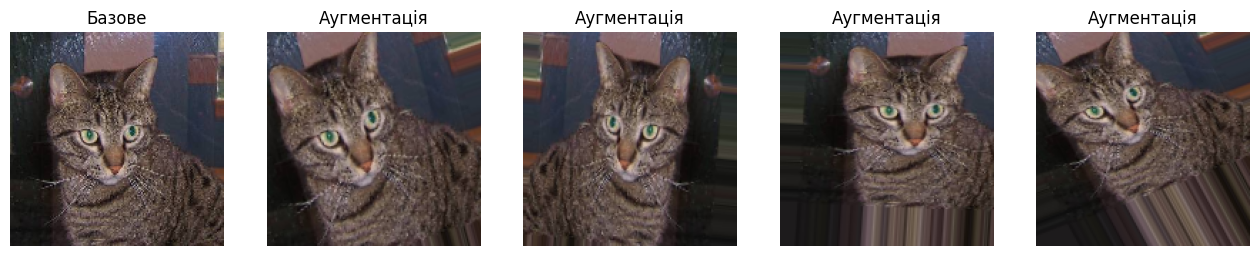

In [10]:
# як аугментація змінює одне зображення
img = load_img('train/cats/cat.1.jpg', target_size=(img_width, img_height))
x = np.expand_dims(img_to_array(img), axis=0)
plt.figure(figsize=(16, 4))
plt.subplot(1, 5, 1); plt.imshow(img); plt.title('Базове'); plt.axis('off')
aug_view = ImageDataGenerator(rotation_range=40, width_shift_range=0.2, height_shift_range=0.2,
                              zoom_range=0.2, horizontal_flip=True, fill_mode='nearest')
for i, batch in enumerate(aug_view.flow(x, batch_size=1)):
    plt.subplot(1, 5, i + 2); plt.imshow(batch[0].astype('uint8')); plt.title('Аугментація'); plt.axis('off')
    if i == 3:
        break
plt.show()

## Модель на основі VGG16

In [11]:
def plot_history(history, title):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='навчальна')
    plt.plot(epochs_range, val_acc, label='перевірочна')
    plt.title(title + ': точність'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='навчальна')
    plt.plot(epochs_range, val_loss, label='перевірочна')
    plt.title(title + ': помилка (loss)'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
    plt.show()

In [12]:



def load_base():
    net = VGG16(weights='imagenet', include_top=False, input_shape=input_shape)
    net.trainable = False
    return net


def make_optimizer(name, lr):
    return Adam(learning_rate=lr) if name == 'adam' else SGD(learning_rate=lr)


def create_model(net):
    """Складена мережа: заморожена згорткова частина + класифікатор з найкращими параметрами лабораторної 9."""
    model = Sequential()
    model.add(Input(shape=input_shape))
    model.add(net)
    model.add(Flatten())
    model.add(Dense(CFG['dense'], activation='relu'))
    model.add(Dropout(CFG['dropout']))
    if CFG['extra_dense']:
        model.add(Dense(CFG['extra_dense'], activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer=make_optimizer(CFG['optimizer'], CFG['lr']), metrics=['accuracy'])
    return model


def train(generator, title):
    net = load_base()
    model = create_model(net)
    history = model.fit(generator, steps_per_epoch=len(generator), epochs=EPOCHS,
                        validation_data=val_generator, validation_steps=len(val_generator), verbose=2)
    plot_history(history, title)
    scores = model.evaluate(test_generator, steps=len(test_generator), verbose=0)
    print(f"{title}: точність на тестових даних {scores[1]*100:.2f}%")
    results.append({'модель': title, 'навчальна, %': history.history['accuracy'][-1] * 100,
                    'перевірочна, %': history.history['val_accuracy'][-1] * 100, 'тестова, %': scores[1] * 100})
    return model, net


def unfreeze(net, n_blocks):
    """Як у лекції: розморожуємо шари, починаючи з першого згорткового шару потрібного блоку."""
    first = {1: 'block5_conv1', 2: 'block4_conv1'}[n_blocks]
    net.trainable = True
    trainable = False
    for layer in net.layers:
        if layer.name == first:
            trainable = True
        layer.trainable = trainable


def fine_tune(model, net, n_blocks, title, epochs=5):
    """Тонке налаштування: розморожуємо n_blocks останніх блоків, мала швидкість навчання, як у лекції."""
    ft = create_model(load_base())
    ft.set_weights(model.get_weights())
    unfreeze(ft.layers[0], n_blocks)
    ft.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=1e-5), metrics=['accuracy'])
    trainable = sum(int(np.prod(w.shape)) for w in ft.trainable_weights)
    print(f"Розморожено блоків: {n_blocks}, параметрів навчається: {trainable:,}")
    history = ft.fit(train_generator, steps_per_epoch=len(train_generator), epochs=epochs,
                     validation_data=val_generator, validation_steps=len(val_generator), verbose=2)
    plot_history(history, title)
    scores = ft.evaluate(test_generator, steps=len(test_generator), verbose=0)
    print(f"{title}: точність на тестових даних {scores[1]*100:.2f}%")
    results.append({'модель': title, 'навчальна, %': history.history['accuracy'][-1] * 100,
                    'перевірочна, %': history.history['val_accuracy'][-1] * 100, 'тестова, %': scores[1] * 100})
    return ft


results = []

## Перенесення навчання без аугментації

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
80/80 - 22s - 271ms/step - accuracy: 0.6740 - loss: 0.5970 - val_accuracy: 0.8350 - val_loss: 0.4409
Epoch 2/15
80/80 - 13s - 168ms/step - accuracy: 0.8330 - loss: 0.4082 - val_accuracy: 0.8600 - val_loss: 0.3479
Epoch 3/15
80/80 - 20s - 248ms/step - accuracy: 0.8662 - loss: 0.3278 - val_accuracy: 0.8790 - val_loss: 0.3069
Epoch 4/15
80/80 - 15s - 185ms/step - accuracy: 0.8882 - loss: 0.2873 - val_accuracy: 0.8810 - val_loss: 0.2893
Epoch 5/15
80/80 - 14s - 173ms/step - accuracy: 0.9032 - loss: 0.2584 - val_accuracy: 0.8840 - val_loss: 0.2739
Epoch 6/15
80/80 - 14s - 178ms/step - accuracy: 0.9028 - loss: 0.2417 - val_accuracy: 0.8880 - val_loss: 0.2618
Epoch 7/15
80/80 - 15s - 186ms/step - accuracy: 0.9118 - loss: 0.2232 - val_accuracy: 0.8900 - val_loss: 0.2552
Epoch 8/15
80/80 - 16s - 194ms/step - accuracy: 0.9187 - loss: 0.2060 - val_accuracy: 0.8870 - val_loss: 0.2523
Epoch 9/15
80/80 - 15s - 183ms/step - accuracy: 0.920

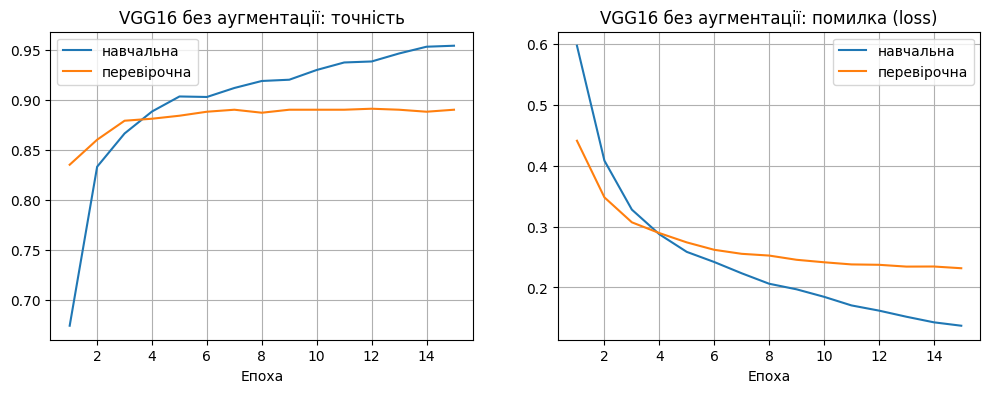

VGG16 без аугментації: точність на тестових даних 89.20%


In [13]:
model_noaug, _ = train(train_noaug_generator, 'VGG16 без аугментації')

## Перенесення навчання з аугментацією (параметри з методички)

Epoch 1/15
80/80 - 38s - 470ms/step - accuracy: 0.6570 - loss: 0.6212 - val_accuracy: 0.8020 - val_loss: 0.4818
Epoch 2/15
80/80 - 33s - 415ms/step - accuracy: 0.7480 - loss: 0.5215 - val_accuracy: 0.8340 - val_loss: 0.3883
Epoch 3/15
80/80 - 34s - 424ms/step - accuracy: 0.7847 - loss: 0.4615 - val_accuracy: 0.8490 - val_loss: 0.3480
Epoch 4/15
80/80 - 35s - 438ms/step - accuracy: 0.8055 - loss: 0.4276 - val_accuracy: 0.8620 - val_loss: 0.3228
Epoch 5/15
80/80 - 34s - 420ms/step - accuracy: 0.8160 - loss: 0.4071 - val_accuracy: 0.8700 - val_loss: 0.3007
Epoch 6/15
80/80 - 34s - 428ms/step - accuracy: 0.8200 - loss: 0.3942 - val_accuracy: 0.8700 - val_loss: 0.2941
Epoch 7/15
80/80 - 35s - 436ms/step - accuracy: 0.8328 - loss: 0.3698 - val_accuracy: 0.8790 - val_loss: 0.2842
Epoch 8/15
80/80 - 35s - 438ms/step - accuracy: 0.8420 - loss: 0.3577 - val_accuracy: 0.8810 - val_loss: 0.2739
Epoch 9/15
80/80 - 35s - 432ms/step - accuracy: 0.8340 - loss: 0.3590 - val_accuracy: 0.8790 - val_loss:

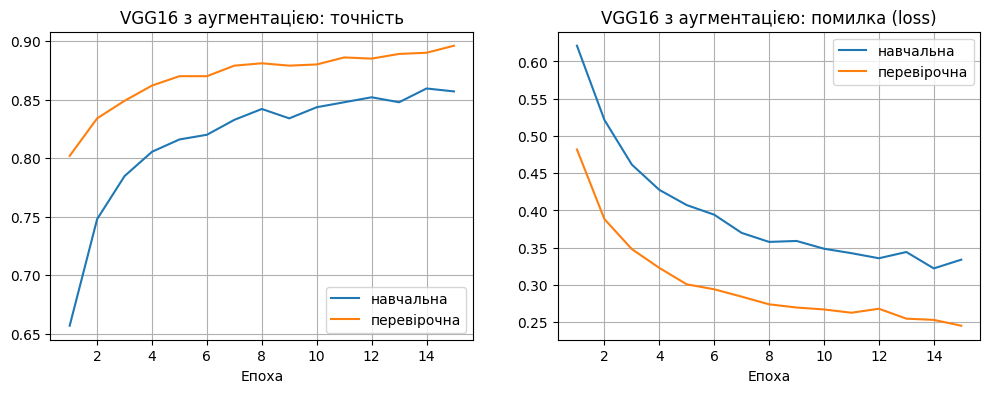

VGG16 з аугментацією: точність на тестових даних 88.90%


In [14]:
model_aug, _ = train(train_generator, 'VGG16 з аугментацією')

## Перенесення навчання зі слабшою аугментацією

Epoch 1/15
80/80 - 38s - 479ms/step - accuracy: 0.6835 - loss: 0.5938 - val_accuracy: 0.8430 - val_loss: 0.4415
Epoch 2/15
80/80 - 35s - 431ms/step - accuracy: 0.8062 - loss: 0.4446 - val_accuracy: 0.8630 - val_loss: 0.3520
Epoch 3/15
80/80 - 35s - 444ms/step - accuracy: 0.8375 - loss: 0.3767 - val_accuracy: 0.8680 - val_loss: 0.3139
Epoch 4/15
80/80 - 35s - 441ms/step - accuracy: 0.8528 - loss: 0.3484 - val_accuracy: 0.8780 - val_loss: 0.2913
Epoch 5/15
80/80 - 36s - 449ms/step - accuracy: 0.8577 - loss: 0.3223 - val_accuracy: 0.8850 - val_loss: 0.2770
Epoch 6/15
80/80 - 35s - 434ms/step - accuracy: 0.8695 - loss: 0.3045 - val_accuracy: 0.8840 - val_loss: 0.2753
Epoch 7/15
80/80 - 35s - 436ms/step - accuracy: 0.8745 - loss: 0.2948 - val_accuracy: 0.8890 - val_loss: 0.2586
Epoch 8/15
80/80 - 35s - 441ms/step - accuracy: 0.8785 - loss: 0.2793 - val_accuracy: 0.8900 - val_loss: 0.2560
Epoch 9/15
80/80 - 36s - 453ms/step - accuracy: 0.8882 - loss: 0.2736 - val_accuracy: 0.8880 - val_loss:

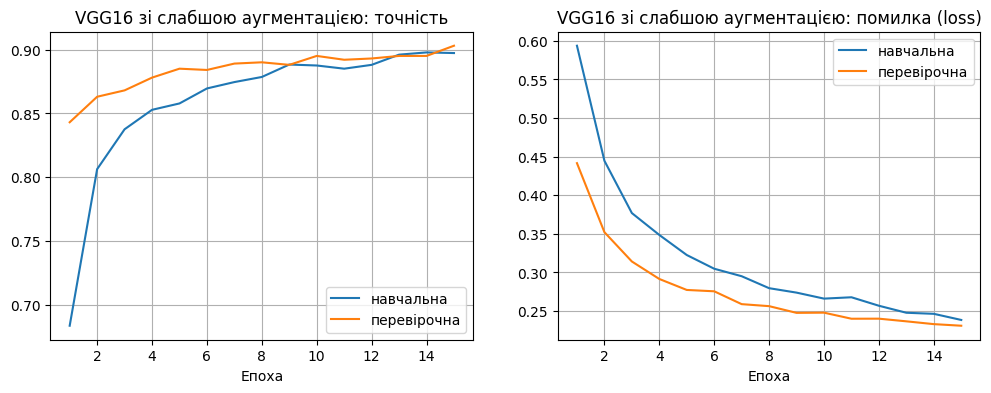

VGG16 зі слабшою аугментацією: точність на тестових даних 88.30%


In [15]:
model_aug2, _ = train(train_generator2, 'VGG16 зі слабшою аугментацією')

## Тонке налаштування: розморожено останній блок (block5)

Розморожено блоків: 1, параметрів навчається: 15,731,713
Epoch 1/5
80/80 - 43s - 537ms/step - accuracy: 0.8643 - loss: 0.3076 - val_accuracy: 0.8990 - val_loss: 0.2410
Epoch 2/5
80/80 - 36s - 449ms/step - accuracy: 0.8823 - loss: 0.2701 - val_accuracy: 0.9210 - val_loss: 0.1982
Epoch 3/5
80/80 - 36s - 445ms/step - accuracy: 0.8960 - loss: 0.2411 - val_accuracy: 0.9370 - val_loss: 0.1762
Epoch 4/5
80/80 - 38s - 473ms/step - accuracy: 0.9043 - loss: 0.2258 - val_accuracy: 0.9470 - val_loss: 0.1719
Epoch 5/5
80/80 - 36s - 444ms/step - accuracy: 0.9093 - loss: 0.2227 - val_accuracy: 0.9410 - val_loss: 0.1645


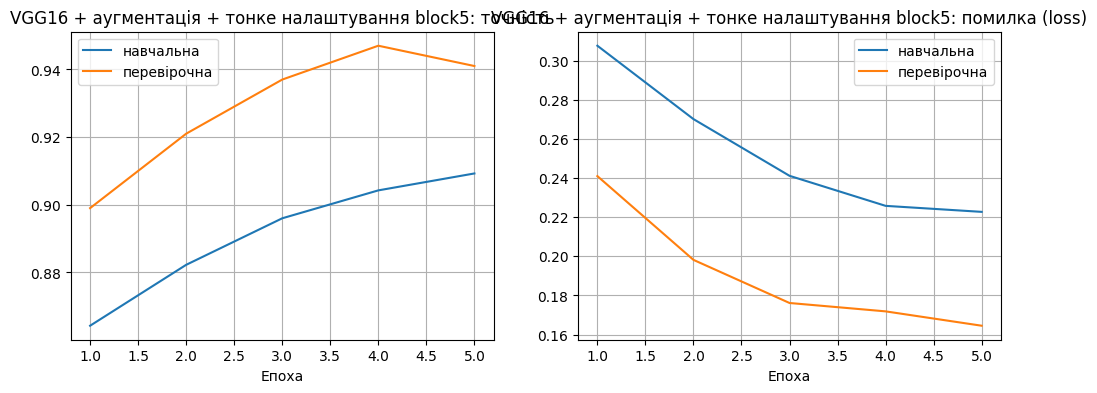

VGG16 + аугментація + тонке налаштування block5: точність на тестових даних 90.70%


In [16]:
model_ft1 = fine_tune(model_aug, None, 1, 'VGG16 + аугментація + тонке налаштування block5')

## Тонке налаштування: розморожено два блоки (block4, block5)

Розморожено блоків: 2, параметрів навчається: 21,631,489
Epoch 1/5
80/80 - 49s - 614ms/step - accuracy: 0.8710 - loss: 0.2895 - val_accuracy: 0.9330 - val_loss: 0.1709
Epoch 2/5
80/80 - 38s - 470ms/step - accuracy: 0.9080 - loss: 0.2221 - val_accuracy: 0.9420 - val_loss: 0.1554
Epoch 3/5
80/80 - 38s - 475ms/step - accuracy: 0.9222 - loss: 0.1849 - val_accuracy: 0.9540 - val_loss: 0.1331
Epoch 4/5
80/80 - 37s - 461ms/step - accuracy: 0.9275 - loss: 0.1708 - val_accuracy: 0.9600 - val_loss: 0.1112
Epoch 5/5
80/80 - 37s - 465ms/step - accuracy: 0.9360 - loss: 0.1523 - val_accuracy: 0.9610 - val_loss: 0.1212


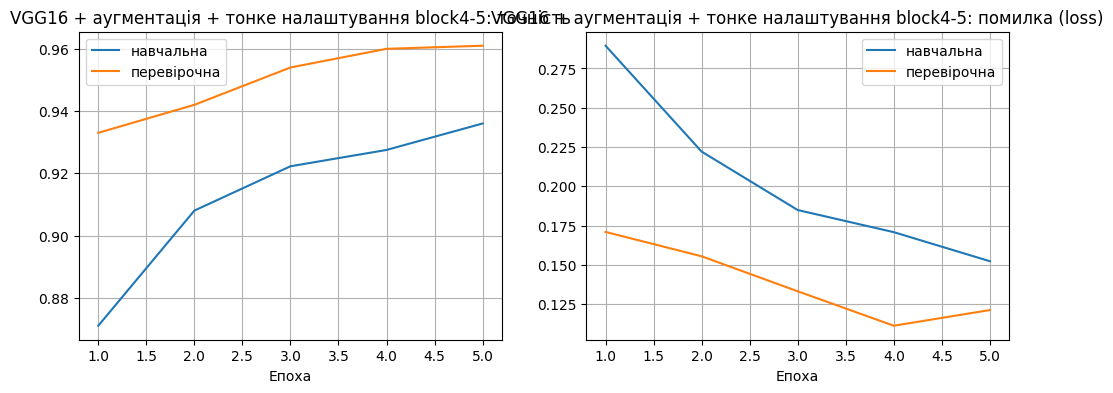

VGG16 + аугментація + тонке налаштування block4-5: точність на тестових даних 94.20%


In [17]:
model_ft2 = fine_tune(model_aug, None, 2, 'VGG16 + аугментація + тонке налаштування block4-5')

## Порівняння і збереження найкращої моделі на Google Диск

In [18]:
table = pd.DataFrame(results)
print(table.round(2))

candidates = [('без аугментації', model_noaug), ('з аугментацією', model_aug), ('слабша аугментація', model_aug2),
              ('тонке налаштування 1 блок', model_ft1), ('тонке налаштування 2 блоки', model_ft2)]
best_title, best_model = max(candidates, key=lambda t: t[1].evaluate(test_generator, steps=len(test_generator), verbose=0)[1])
print('Найкраща модель:', best_title)

save_dir = '/content/drive/MyDrive/Lab10_models'
os.makedirs(save_dir, exist_ok=True)
best_model.save(os.path.join(save_dir, 'vgg16_aug_best.h5'), include_optimizer=False)
table.to_csv(os.path.join(save_dir, 'vgg16_aug_best_results.csv'), index=False)
!ls -lh {save_dir}

                                              модель  навчальна, %  \
0                              VGG16 без аугментації         95.40   
1                               VGG16 з аугментацією         85.70   
2                      VGG16 зі слабшою аугментацією         89.72   
3    VGG16 + аугментація + тонке налаштування block5         90.93   
4  VGG16 + аугментація + тонке налаштування block4-5         93.60   

   перевірочна, %  тестова, %  
0            89.0        89.2  
1            89.6        88.9  
2            90.3        88.3  
3            94.1        90.7  
4            96.1        94.2  


Найкраща модель: тонке налаштування 2 блоки
total 90M
-rw------- 1 root root 90M Oct 31 11:17 vgg16_aug_best.h5
-rw------- 1 root root 627 Oct 31 11:17 vgg16_aug_best_results.csv


## Розпізнавання власних зображень (ті самі, що в лабораторних роботах 7-9)

In [19]:
img_dirs = glob.glob('/content/drive/MyDrive/**/images_cats_dogs', recursive=True)
print(img_dirs)
assert img_dirs, 'Папку images_cats_dogs не знайдено на Google Диску'
for f in glob.glob(os.path.join(img_dirs[0], '*.jpg')):
    shutil.copy(f, '/content/')
print(len(glob.glob('/content/*.jpg')), 'зображень')

['/content/drive/MyDrive/Deep learning/images_cats_dogs']
47 зображень


In [20]:
def prepare(x):
    return x / 255.


def recognize(pattern, title):
    names = sorted(glob.glob(pattern))
    cols = 5
    rows = (len(names) + cols - 1) // cols
    plt.figure(figsize=(3 * cols, 3.4 * rows), dpi=60)
    correct = 0
    for i, fn in enumerate(names):
        img = load_img(fn, target_size=(img_width, img_height))
        x = np.expand_dims(prepare(img_to_array(img)), axis=0)
        p = float(best_model.predict(x, verbose=0)[0][0])     # ймовірність класу dogs
        pred = 'dog' if p > 0.5 else 'cat'
        true = 'dog' if 'dog' in os.path.basename(fn) else 'cat'
        correct += pred == true
        conf = p if pred == 'dog' else 1 - p
        print(f"{os.path.basename(fn)}: правильно - {true}, мережа - {pred} ({conf*100:.1f}%) {'✓' if pred == true else '✗'}")
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(f"{os.path.basename(fn)}\n{pred} ({conf*100:.1f}%)", color='green' if pred == true else 'red')
        plt.axis('off')
    plt.suptitle(title)
    plt.show()
    print(f"Правильно розпізнано: {correct} з {len(names)}")

cat_01.jpg: правильно - cat, мережа - cat (99.9%) ✓
cat_02.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_03.jpg: правильно - cat, мережа - dog (94.5%) ✗
cat_04.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_05.jpg: правильно - cat, мережа - cat (99.9%) ✓
cat_06.jpg: правильно - cat, мережа - cat (99.9%) ✓
cat_07.jpg: правильно - cat, мережа - cat (69.9%) ✓
cat_08.jpg: правильно - cat, мережа - dog (96.6%) ✗
cat_09.jpg: правильно - cat, мережа - dog (59.5%) ✗
cat_10.jpg: правильно - cat, мережа - cat (98.6%) ✓


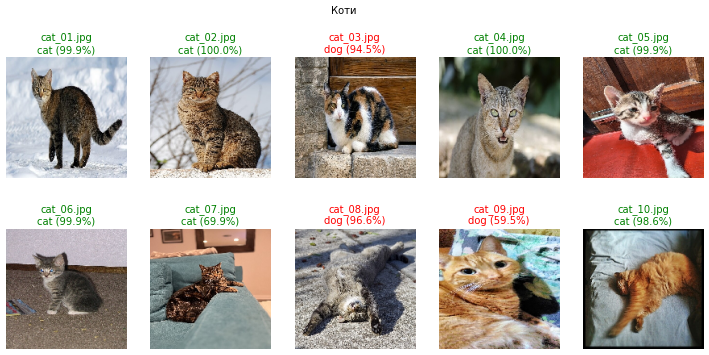

Правильно розпізнано: 7 з 10
dog_01.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_02.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_03.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_04.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_05.jpg: правильно - dog, мережа - dog (99.9%) ✓
dog_06.jpg: правильно - dog, мережа - dog (99.8%) ✓
dog_07.jpg: правильно - dog, мережа - dog (98.2%) ✓
dog_08.jpg: правильно - dog, мережа - dog (78.3%) ✓
dog_09.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_10.jpg: правильно - dog, мережа - dog (100.0%) ✓


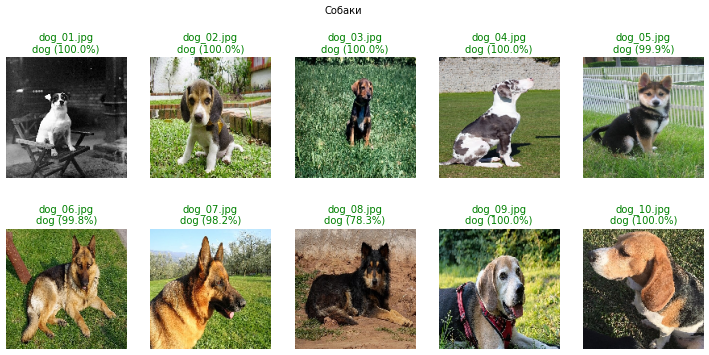

Правильно розпізнано: 10 з 10


In [21]:
recognize('cat_*.jpg', 'Коти')
recognize('dog_*.jpg', 'Собаки')

hard_cat_01.jpg: правильно - cat, мережа - dog (99.0%) ✗
hard_cat_02.jpg: правильно - cat, мережа - dog (100.0%) ✗
hard_cat_03.jpg: правильно - cat, мережа - dog (99.9%) ✗
hard_cat_04.jpg: правильно - cat, мережа - cat (93.6%) ✓
hard_cat_05.jpg: правильно - cat, мережа - dog (96.5%) ✗
hard_cat_06.jpg: правильно - cat, мережа - dog (77.7%) ✗
hard_cat_07.jpg: правильно - cat, мережа - cat (98.7%) ✓
hard_cat_08.jpg: правильно - cat, мережа - cat (99.8%) ✓
hard_cat_09.jpg: правильно - cat, мережа - dog (98.3%) ✗
hard_cat_10.jpg: правильно - cat, мережа - cat (81.0%) ✓
hard_dog_01.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_02.jpg: правильно - dog, мережа - dog (90.6%) ✓
hard_dog_03.jpg: правильно - dog, мережа - dog (78.8%) ✓
hard_dog_04.jpg: правильно - dog, мережа - dog (98.2%) ✓
hard_dog_05.jpg: правильно - dog, мережа - dog (99.8%) ✓
hard_dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_07.jpg: правильно - dog, мережа - dog (99.4%) ✓
hard_dog_08.jpg: правильно -

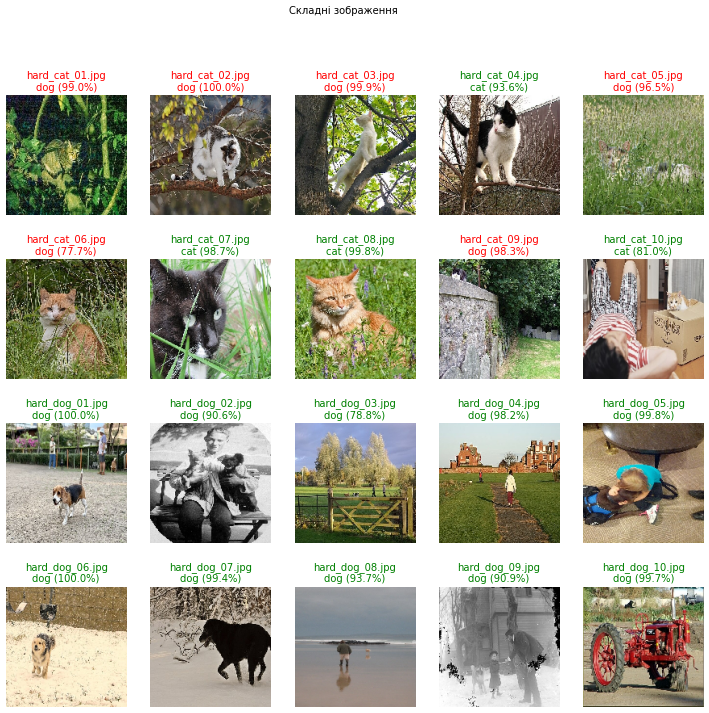

Правильно розпізнано: 14 з 20


In [22]:
recognize('hard_*.jpg', 'Складні зображення')

crop_cat_02.jpg: правильно - cat, мережа - dog (81.8%) ✗
crop_cat_03.jpg: правильно - cat, мережа - dog (98.4%) ✗
crop_cat_05.jpg: правильно - cat, мережа - dog (92.4%) ✗
crop_cat_06.jpg: правильно - cat, мережа - cat (56.0%) ✓
crop_cat_07.jpg: правильно - cat, мережа - cat (97.6%) ✓
crop_cat_08.jpg: правильно - cat, мережа - cat (100.0%) ✓
crop_dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓


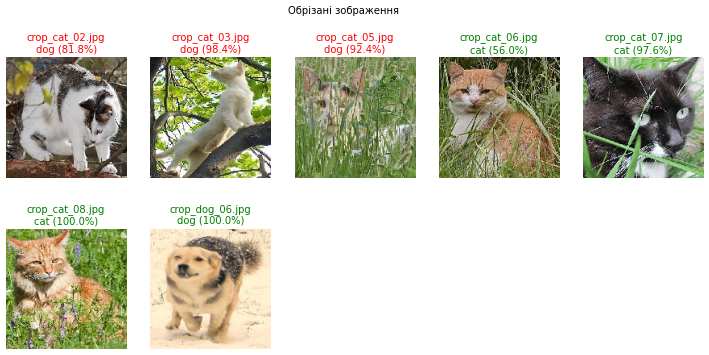

Правильно розпізнано: 4 з 7


In [23]:
recognize('crop_*.jpg', 'Обрізані зображення')